# ETF allocation sensitivity

Seven prespecified comparisons isolate the risk target, covariance estimate and
strategic weighting rule. Each path uses all 1,975 development sessions and a
10 bp fee per traded side. These are development comparisons, not held-out
performance. The reference reproduces the earlier combined-control ledger.


In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'pyproject.toml').exists())
report = root/'reports/etf_sensitivity_v3'
raw = (report/'export-manifest.json').read_bytes()
manifest = json.loads(raw)
assert (report/'COMPLETE').read_text().strip() == hashlib.sha256(raw).hexdigest()
assert manifest['complete'] and not manifest['holdout_evaluated']
for name, pin in manifest['outputs_sha256'].items():
    assert hashlib.sha256((report/name).read_bytes()).hexdigest() == pin
daily = pd.read_parquet(report/'daily-paths.parquet')
metrics = pd.read_csv(report/'path-metrics.csv', index_col='arm', float_precision='round_trip')
wealth = daily.pivot(index='session', columns='arm', values='close_nav').sort_index()
returns = daily.pivot(index='session', columns='arm', values='daily_return').sort_index()
assert wealth.shape == returns.shape == (1975, 7)
assert wealth.notna().all().all() and returns.notna().all().all()
for arm in wealth:
    nav = np.r_[100000., wealth[arm].to_numpy()]
    r = nav[1:]/nav[:-1]-1
    np.testing.assert_array_equal(r, returns[arm])
    np.testing.assert_allclose(r.mean()/r.std(ddof=1)*np.sqrt(252),
        metrics.loc[arm, 'annual_sharpe_zero_cash_reference'], atol=1e-12, rtol=0)
display(metrics[['annual_return_252_session_convention',
    'annual_volatility_sample_ddof1', 'annual_sharpe_zero_cash_reference',
    'maximum_close_nav_drawdown', 'total_fee_money']].round(4))


,annual_return_252_session_convention,annual_volatility_sample_ddof1,annual_sharpe_zero_cash_reference,maximum_close_nav_drawdown,total_fee_money
arm,,,,,
covariance_ewma63_only,0.0518,0.0777,0.6893,-0.1122,1508.8429
covariance_ledoit_wolf_only,0.0532,0.0789,0.6963,-0.1122,1505.1037
reference_sample_target10,0.0524,0.0776,0.6972,-0.1122,1526.0105
target05_only,0.0346,0.0483,0.7273,-0.0827,1267.3352
target15_only,0.0566,0.0860,0.6832,-0.1122,1382.2262
weight_inverse_vol_only,0.0601,0.0701,0.8676,-0.1106,1671.1295
weight_risk_budget_only,0.0610,0.0651,0.9415,-0.1106,1738.0787


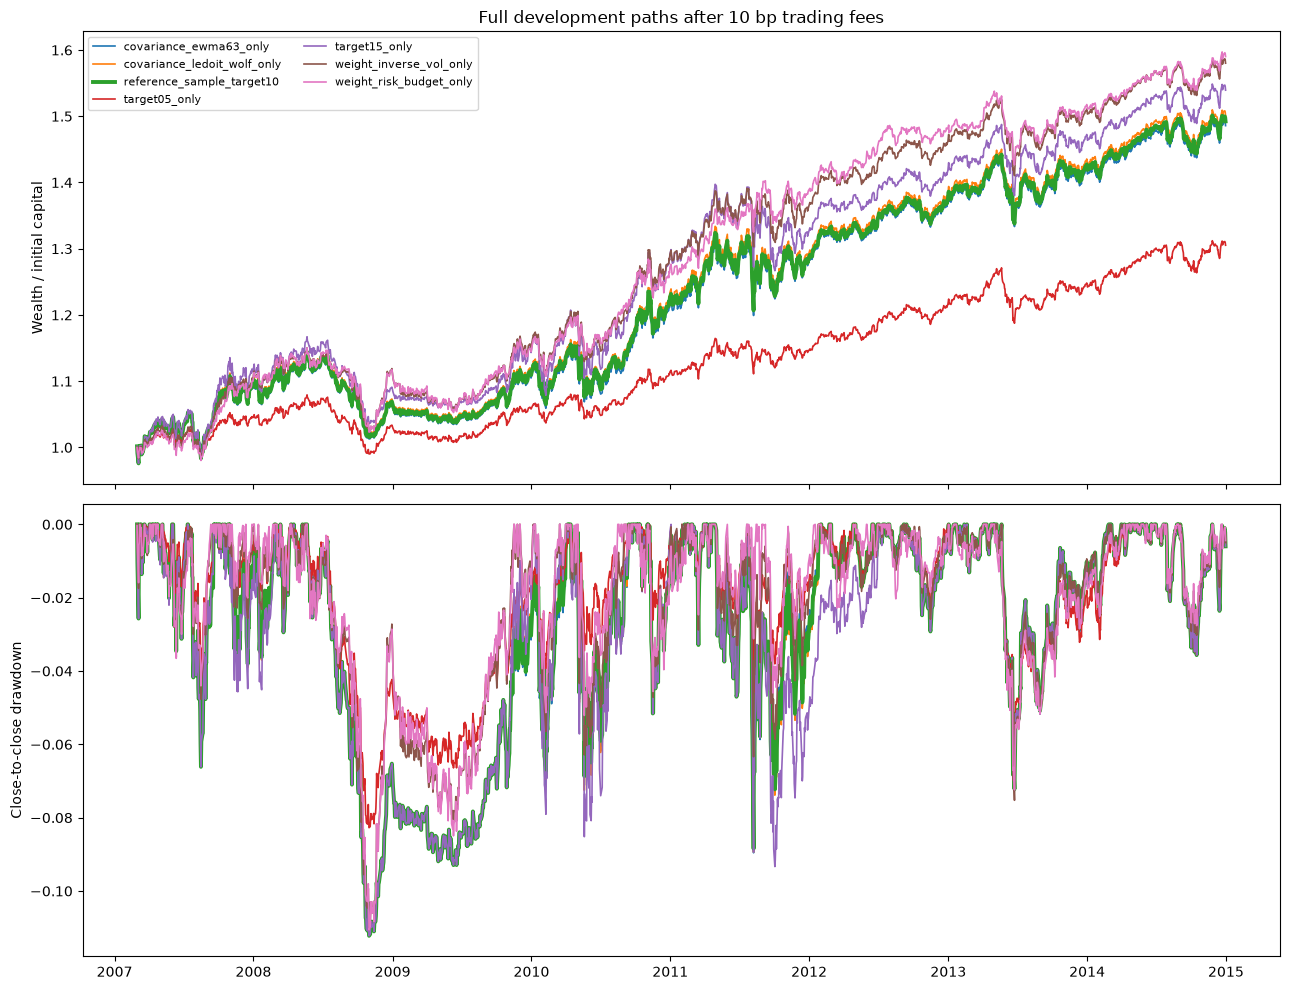

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)
dates = pd.to_datetime(wealth.index)
for arm in wealth:
    nav = wealth[arm].to_numpy()
    width = 2.8 if arm == 'reference_sample_target10' else 1.2
    axes[0].plot(dates, nav/100000., label=arm, linewidth=width)
    peak = np.maximum.accumulate(np.r_[100000., nav])[1:]
    axes[1].plot(dates, nav/peak-1, linewidth=width)
axes[0].set_ylabel('Wealth / initial capital')
axes[1].set_ylabel('Close-to-close drawdown')
axes[0].legend(fontsize=8, ncol=2)
axes[0].set_title('Full development paths after 10 bp trading fees')
fig.tight_layout()
plt.show()


,arm,block_sessions,annualized_mean_difference,lower,upper
0,covariance_ewma63_only,21,-0.00055,-0.00166,0.00057
1,covariance_ledoit_wolf_only,21,0.00082,-0.00039,0.00198
2,reference_sample_target10,21,0.00000,0.00000,0.00000
3,target05_only,21,-0.01893,-0.03880,-0.00012
4,target15_only,21,0.00466,-0.00485,0.01377
5,weight_inverse_vol_only,21,0.00675,-0.00690,0.02112
6,weight_risk_budget_only,21,0.00722,-0.01400,0.02924
7,covariance_ewma63_only,63,-0.00055,-0.00160,0.00055
8,covariance_ledoit_wolf_only,63,0.00082,-0.00029,0.00192
9,reference_sample_target10,63,0.00000,0.00000,0.00000


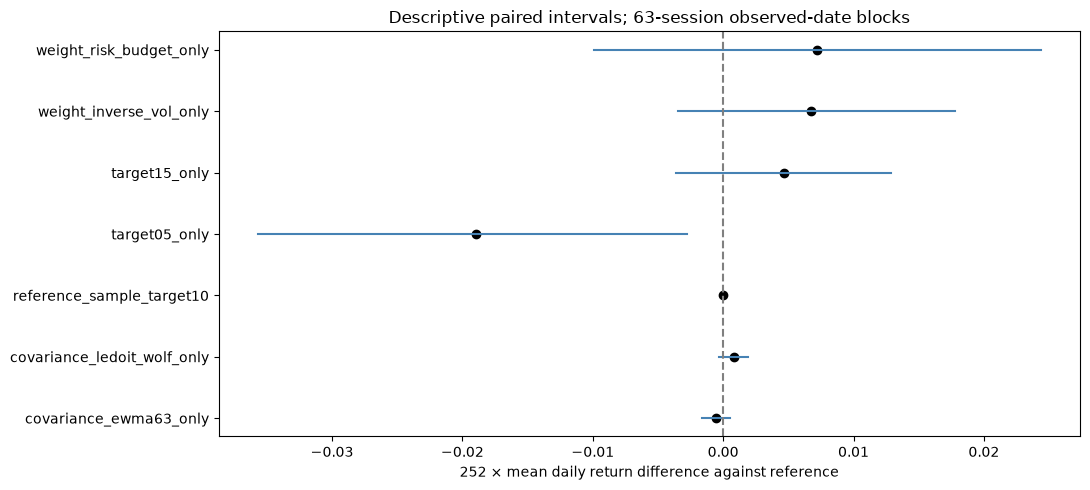

In [3]:
reference = 'reference_sample_target10'
delta = returns.subtract(returns[reference], axis=0)
records = []
for block in [21, 63, 126]:
    rng = np.random.default_rng(20261018 + block)
    starts = rng.integers(0, len(delta), (2000, int(np.ceil(len(delta)/block))))
    # Prefix sums reproduce circular observed-date blocks without a large tensor.
    values = delta.to_numpy()
    doubled = np.concatenate([values, values], axis=0)
    prefix = np.vstack([np.zeros((1, 7)), doubled.cumsum(axis=0)])
    samples = np.zeros((2000, 7))
    remaining = len(delta)
    for j in range(starts.shape[1]):
        length = min(block, remaining)
        samples += prefix[starts[:, j]+length]-prefix[starts[:, j]]
        remaining -= length
    samples *= 252/len(delta)
    lower, upper = np.quantile(samples, [.025, .975], axis=0)
    for j, arm in enumerate(delta):
        records.append(dict(arm=arm, block_sessions=block,
            annualized_mean_difference=252*delta[arm].mean(),
            lower=lower[j], upper=upper[j]))
intervals = pd.DataFrame(records)
display(intervals.round(5))
fig, ax = plt.subplots(figsize=(11, 5))
subset = intervals[intervals.block_sessions == 63].set_index('arm')
for y, (arm, row) in enumerate(subset.iterrows()):
    ax.plot([row.lower, row.upper], [y, y], color='steelblue')
    ax.scatter(row.annualized_mean_difference, y, color='black')
ax.set_yticks(range(7), subset.index)
ax.axvline(0, color='grey', linestyle='--')
ax.set_xlabel('252 × mean daily return difference against reference')
ax.set_title('Descriptive paired intervals; 63-session observed-date blocks')
fig.tight_layout()
plt.show()


## Does the forecast choice improve the allocation?

The covariance study selects EWMA with a 63-observation half-life by mean
QLIKE on all 94 common mature dates for the eight-ETF, 63-return panel.
This criterion is separate from portfolio performance. The matched economic
comparison keeps all 95 signal clocks, source rows, trend masks, equal strategic
budgets, target volatility and fees fixed; only the covariance estimator changes.


In [4]:
integration = root/'reports/etf_covariance_integration_v1'
raw = (integration/'export-manifest.json').read_bytes()
link = json.loads(raw)
assert (integration/'COMPLETE').read_text().strip() == hashlib.sha256(raw).hexdigest()
assert link['complete'] and not link['holdout_evaluated']
assert not link['selection_based_on_portfolio_scores']
for name, pin in link['outputs_sha256'].items():
    assert hashlib.sha256((integration/name).read_bytes()).hexdigest() == pin
losses = pd.read_csv(integration/'paired-forecast-losses.csv', index_col=0,
                     float_precision='round_trip')
assert losses.shape == (94, 8) and losses.notna().all().all()
assert losses.mean().idxmin() == link['selected_covariance_recipe']
display(losses.mean().sort_values().rename('Mean QLIKE; lower is better').to_frame())
economic = pd.read_csv(integration/'matched-path-metrics.csv', index_col='arm')
display(economic[['annual_return_252_session_convention',
    'annual_sharpe_zero_cash_reference', 'total_fee_money']])
print(link['interpretation'])


,Mean QLIKE; lower is better
ewma_halflife63,-8.597526
pca_K3,-8.590978
sample_ddof1,-8.582195
pca_K5,-8.581941
oas,-8.565930
ledoit_wolf,-8.554335
constant_correlation_fixed0p5,-8.545346
pca_K1,-8.513905


,annual_return_252_session_convention,annual_sharpe_zero_cash_reference,total_fee_money
arm,,,
reference_sample_target10,0.052403,0.697155,1526.010450
covariance_ewma63_only,0.051822,0.689319,1508.842894


The forecast-selected EWMA has lower development Sharpe than sample. Forecast selection and economic evaluation answer different questions; this is reused-development integration, not an independent test.


The risk-budget weighting path has the highest development Sharpe
in this comparison. That does not establish a future edge or select the final
integrated strategy. The intervals resample observed dates; they generate no
market prices. They measure paired arithmetic mean-return differences, not
Sharpe or CAGR uncertainty, and do not adjust for multiple comparisons.

Accounting was independently reconciled from saved ownership components,
fees, trades and NAV. This is not an independent reconstruction of raw prices.
The 2015–2017 final period remains sealed.
